In [ ]:
# Import Library
import pandas as pd
import numpy as np
import re
import string
from nltk.tokenize import word_tokenize
from nltk.stem import WordNetLemmatizer
from sklearn. feature_extraction. text import TfidfVectorizer
from sklearn.cluster import KMeans
from sklearn. decomposition import PCA
import matplotlib.pyplot as plt

In [4]:
# Load dataset
file_path = "Text.csv"
df = pd.read_csv(r"D:\IT DEL\2026\certan\tugas\CERTAN\W6\s3\tmdb_5000_movies.csv.gz")

# Hanya mengambil kolom message untuk klasterisasi
df = df.rename(columns={'Message': 'text'})

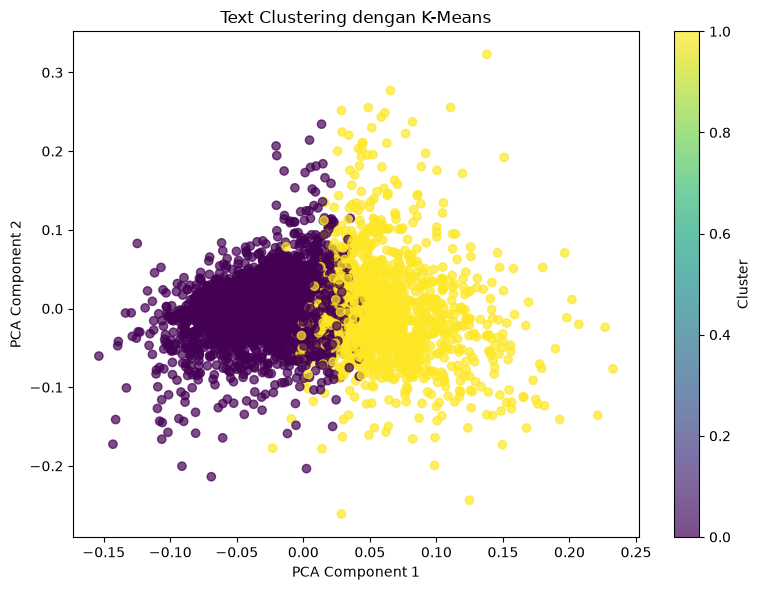

In [9]:

# Inisialisasi Lemmatizer
lemmatizer = WordNetLemmatizer()

# Pastikan kolom text tersedia
if 'text' not in df.columns:
    if 'overview' in df.columns:
        df = df.rename(columns={'overview': 'text'})
    else:
        raise KeyError(
            f"Kolom text tidak ditemukan. "
            f"Kolom tersedia: {df.columns.tolist()}"
        )

# Hapus data teks kosong
df = df.dropna(subset=['text']).copy()

# Fungsi preprocessing teks
def clean_text(text):
    text = str(text).lower()  # Lowercasing
    text = re.sub(r'\d+', '', text)  # Hapus angka
    text = text.translate(
        str.maketrans('', '', string.punctuation)
    )  # Hapus tanda baca

    words = word_tokenize(text)  # Tokenisasi
    words = [
        lemmatizer.lemmatize(word)
        for word in words
    ]  # Lemmatization

    return ' '.join(words)

# Terapkan preprocessing ke teks
df['clean_text'] = df['text'].apply(clean_text)

# Hapus teks kosong setelah preprocessing
df = df[df['clean_text'].str.strip() != ''].copy()

# Konversi teks ke vektor TF-IDF
vectorizer = TfidfVectorizer(stop_words='english')
X = vectorizer.fit_transform(df['clean_text'])

# Tentukan jumlah klaster
num_clusters = 2

if X.shape[0] < num_clusters or X.shape[1] < 2:
    raise ValueError(
        "Jumlah dokumen atau fitur tidak cukup untuk clustering/PCA."
    )

kmeans = KMeans(
    n_clusters=num_clusters,
    random_state=42,
    n_init=10
)

df['cluster'] = kmeans.fit_predict(X)

# Visualisasi dengan PCA
pca = PCA(n_components=2)
X_pca = pca.fit_transform(X.toarray())

plt.figure(figsize=(8, 6))

plt.scatter(
    X_pca[:, 0],
    X_pca[:, 1],
    c=df['cluster'],
    cmap='viridis',
    alpha=0.7
)

plt.xlabel("PCA Component 1")
plt.ylabel("PCA Component 2")
plt.title("Text Clustering dengan K-Means")
plt.colorbar(label='Cluster')
plt.tight_layout()
plt.show()